**Сначала переключитесь на графический процессор!**

# 6. Практическое занятие. Свёрточные нейронные сети (CNN)

**Цель работы:** Познакомиться с архитектурой CNN, научиться строить и обучать свёрточные сети для классификации изображений, визуализировать карты активации и экспериментировать с архитектурными решениями.

В этой практике мы будем использовать датасет CIFAR-10 (32x32 цветных изображения, 10 классов).

## 0. Импорты и подготовка данных

Импортируем необходимые библиотеки и загружаем CIFAR-10.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import time

# Для воспроизводимости
torch.manual_seed(42)
np.random.seed(42)

# Устройство
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')



Using device: cuda


In [ ]:
# Загрузка данных CIFAR-10
# Для ускорения возьмём подвыборку (первые 10000 обучающих, 2000 тестовых)
# Но можно и полный датасет, если есть время.

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.247, 0.243, 0.261))
])

train_full = datasets.CIFAR10('./data', train=True, download=True, transform=transform)
test_full = datasets.CIFAR10('./data', train=False, download=True, transform=transform)

# Для экспериментов возьмём подвыборку (ускорит обучение)
num_train = 10000
num_val = 2000
indices = torch.randperm(len(train_full))
train_indices = indices[:num_train]
val_indices = indices[num_train:num_train+num_val]

train_dataset = Subset(train_full, train_indices)
val_dataset = Subset(train_full, val_indices)
test_dataset = test_full

print(f'Train samples: {len(train_dataset)}')
print(f'Val samples: {len(val_dataset)}')
print(f'Test samples: {len(test_dataset)}')

100%|██████████| 170M/170M [01:10<00:00, 2.42MB/s]


Train samples: 10000
Val samples: 2000
Test samples: 10000


In [ ]:
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

print(f'Train size: {len(train_dataset)}, Test size: {len(test_dataset)}')

Train size: 10000, Test size: 10000


## 1. Построение базовой CNN (10 мин)

Определим класс `SimpleCNN` с двумя свёрточными слоями, пулингом и полносвязными слоями.

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # 3 - кол-во входных каналов
        # 32 - кол-во выходных каналов (ядер)
        # kernel_size=3 - размер ядра свертки
        # padding=1 - отступ
        # на выходе 32 карты признаков размером 32*32
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1) # 32*32*3 -> 32*32*32

        # уменьшение размерности в 2 раза по каждой оси
        self.pool = nn.MaxPool2d(2) # пример: 32*32*32 -> 16*16*32

        # 32 - кол-во входных каналов
        # 64 - кол-во выходных каналов (ядер)
        # kernel_size=3 - размер ядра свертки
        # padding=1 - отступ
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1) # 16*16*32 -> 16*16*64


        # матрица весов (256 * 64*8*8) умножается на вектор длины 64*8*8, полученный из входных данных
        self.fc1 = nn.Linear(64*8*8, 256)

        # матрица весов (10 * 256) умножается на вектор длины 256, полученный из входных данных
        self.fc2 = nn.Linear(256, 10)

        # отключение половины нейронов
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        # x - входное изображение

        x = self.pool(F.relu(self.conv1(x)))
        # теперь x - 32 карты признаков размером 16*16

        x = self.pool(F.relu(self.conv2(x)))
        # теперь x - 64 карты признаков размером 8x8

        # растягиваем тензор 64*8*8 в один большой вектор.
        x = x.view(x.size(0), -1)  # flatten

        x = self.dropout(F.relu(self.fc1(x)))
        # теперь х - вектор из 256 результатов активации нейронов

        x = self.fc2(x)
        # теперь х - вектор из 10 чисел, имеющих значения (-inf; inf)

        # Т.к. ниже написан выбор кросс-энтропии в качестве функции потерь
        # для многоклассовой классификации
        # criterion = nn.CrossEntropyLoss()
        # то к х после завершения данного метода
        # ещё дополнительно применится функция softmaх,
        # которая отмасштабирует значения х до отрезка [0; 1]
        return x

model = SimpleCNN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Посчитаем количество параметров
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'Количество обучаемых параметров: {count_parameters(model)}')

Количество обучаемых параметров: 1070794


## 2. Обучение и базовая оценка

Напишем функцию для одной эпохи обучения и оценки. Обучим модель на 5 эпохах и сохраним историю потерь.

Epoch 1/5, Train Loss: 1.8135, Val Loss: 1.4655, Val Acc: 0.4822
Epoch 2/5, Train Loss: 1.4261, Val Loss: 1.3036, Val Acc: 0.5385
Epoch 3/5, Train Loss: 1.2693, Val Loss: 1.2257, Val Acc: 0.5657
Epoch 4/5, Train Loss: 1.1366, Val Loss: 1.1751, Val Acc: 0.5817
Epoch 5/5, Train Loss: 1.0479, Val Loss: 1.1366, Val Acc: 0.5892

Финальная точность на тесте: 0.5892
Сравнение с MLP: MLP давал точность около 0.5, наша CNN показывает значительное улучшение.


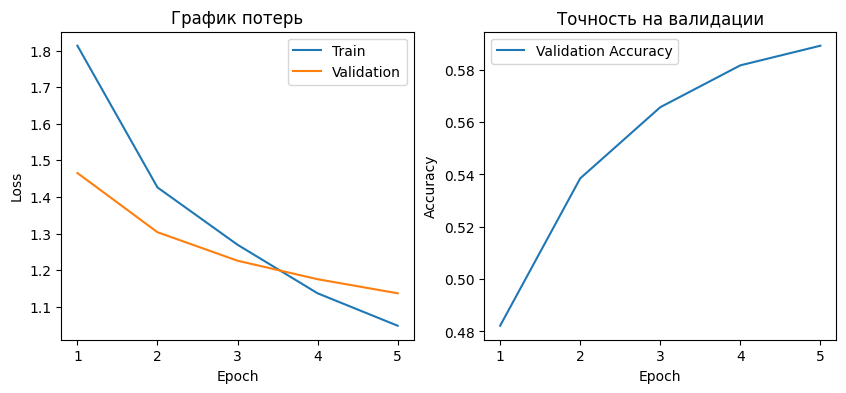

In [ ]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    running_loss = 0.0
    for images, labels in loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
    return running_loss / len(loader.dataset)

def evaluate(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return running_loss / len(loader.dataset), correct / total

num_epochs = 5
train_losses = []
val_losses = []
val_accs = []

for epoch in range(num_epochs):
    train_loss = train_epoch(model, train_loader, optimizer, criterion)
    val_loss, val_acc = evaluate(model, test_loader, criterion)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_accs.append(val_acc)
    print(f'Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}')

print(f'\nФинальная точность на тесте: {val_accs[-1]:.4f}')

# Сравнение с MLP из занятия 5 (ожидаем ~0.5)
print('Сравнение с MLP: MLP давал точность около 0.5, наша CNN показывает значительное улучшение.')

# Построим графики потерь
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(range(1, num_epochs+1), train_losses, label='Train')
plt.plot(range(1, num_epochs+1), val_losses, label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('График потерь')

plt.subplot(1,2,2)
plt.plot(range(1, num_epochs+1), val_accs, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Точность на валидации')
plt.show()

## 3. Визуализация карт активации

Посмотрим, что именно выучил первый свёрточный слой. Для этого выберем несколько тестовых изображений и выведем карты активации (первые несколько каналов) после первого свёрточного слоя (до пулинга).

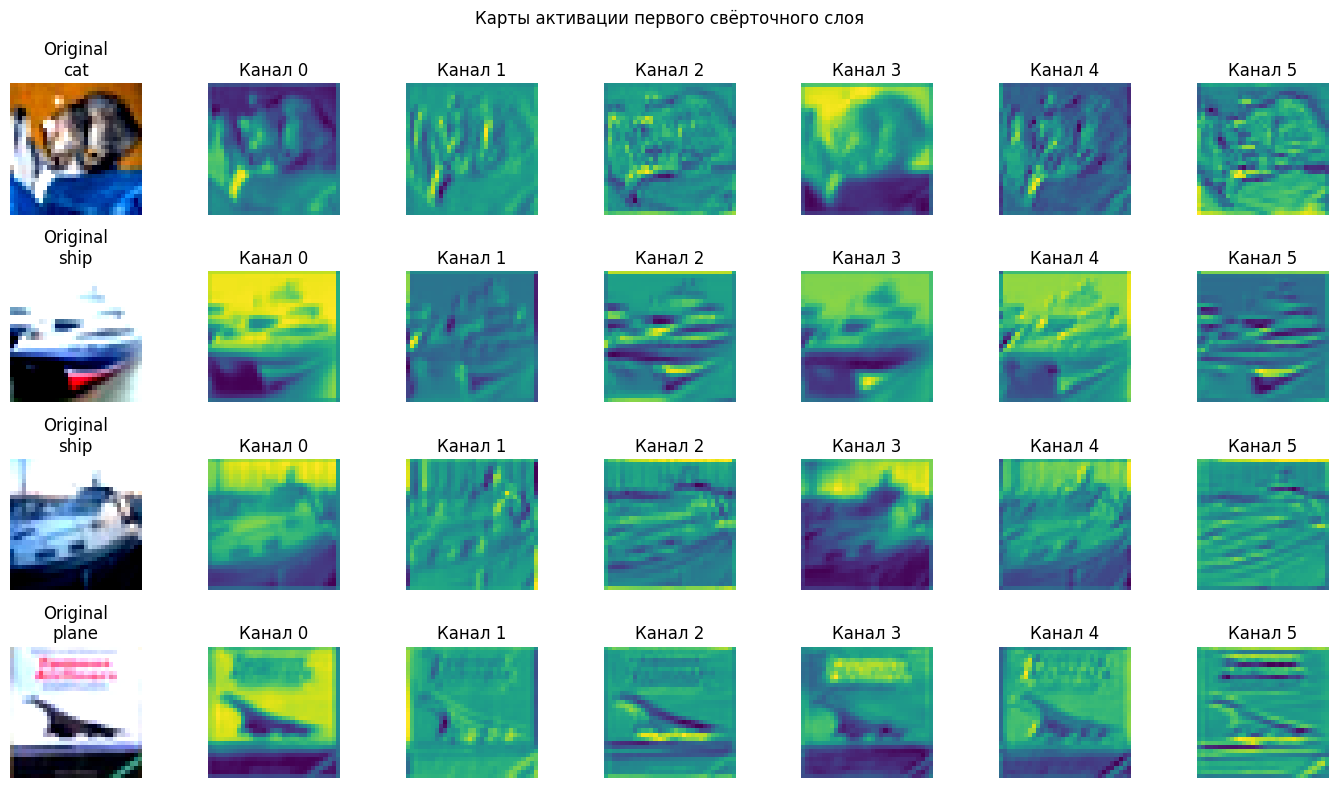

In [ ]:
# Функция для получения активаций через forward hook
activations = {}
def hook_fn(name):
    def hook(model, input, output):
        activations[name] = output.detach()
    return hook

# Регистрируем хук на conv1
hook = model.conv1.register_forward_hook(hook_fn('conv1'))

# Берём несколько тестовых изображений
dataiter = iter(test_loader)
images, labels = next(dataiter)
images = images[:4]  # возьмём 4 картинки

# Прогоняем через сеть (без градиентов)
with torch.no_grad():
    outputs = model(images)

# Получаем активации
acts = activations['conv1']  # (4, 32, 32, 32)

# Визуализируем исходные изображения и карты активаций (первые 6 каналов)
fig, axes = plt.subplots(4, 7, figsize=(14, 8))
for i in range(4):
    # Исходное изображение (восстанавливаем из нормализации)
    img = images[i].cpu().numpy().transpose(1,2,0)
    img = img * 0.5 + 0.5  # обратная нормализация
    axes[i, 0].imshow(np.clip(img, 0, 1))
    axes[i, 0].set_title(f'Original\n{classes[labels[i]]}')
    axes[i, 0].axis('off')

    # 6 случайных каналов
    for j in range(6):
        channel_idx = j  # можно взять первые 6, но для разнообразия используем случайные
        ax = axes[i, j+1]
        ax.imshow(acts[i, channel_idx].cpu(), cmap='viridis')
        ax.set_title(f'Канал {channel_idx}')
        ax.axis('off')

plt.suptitle('Карты активации первого свёрточного слоя')
plt.tight_layout()
plt.show()

hook.remove()


Задание: Опишите, какие признаки активируют разные каналы (контуры, текстуры, цвета). Заметно ли, что карты примерно соответствуют очертаниям объектов? (Из-за маленького размера 32x32 и нормализации это может быть неочевидно, но попытайтесь увидеть границы.)

Ответ (для конкретно этих карт признаков): заметно, что карты соответствуют очертаниям объектов (особенно заметны для самолета четкие границы с фоном). Также видно, что каждый канал выделяет определенный цвет (например, 0 канал выделяет более светлые участки, 3 канал выделяет более красные участки).

## 4. Эксперименты с архитектурой

Теперь вы самостоятельно модифицируете архитектуру и сравниваете результаты. Выберите **2-3** варианта из предложенных ниже, реализуйте соответствующие модели, обучите их на **3-5 эпохах** (для экономии времени) и запишите точность и количество параметров.

**Варианты модификаций:**
1. Увеличить число каналов: `conv1(3, 64)`, `conv2(64, 128)`.
2. Добавить третий свёрточный блок (Conv+Pool).
3. Заменить MaxPool на `stride=2` в свёртке (убрать явный пулинг).
4. Изменить размер ядра на 5 (учесть изменение padding для сохранения размера).
5. Добавить `BatchNorm2d` после каждой свёртки.
6. Заменить `Linear` на Global Average Pooling: `x = torch.mean(x, [2,3])` и затем один линейный слой.

Для каждой модели заполняйте таблицу (можно просто выводить на печать).

In [ ]:
# Пример реализации одной из модификаций (увеличение числа каналов)
class WiderCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(128*8*8, 256)
        self.fc2 = nn.Linear(256, 10)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

# третий сверточный слой
class ThreeConvCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(128*4*4, 256)
        self.fc2 = nn.Linear(256, 10)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)
        return x


# замена ядра на 5*5, padding = (kernel_size - 1) / 2 = 2
class BigKernelCNN(nn.Module):
  def __init__(self):
      super().__init__()
      self.conv1 = nn.Conv2d(3, 64, kernel_size=5, padding=2)
      self.pool = nn.MaxPool2d(2)
      self.conv2 = nn.Conv2d(64, 128, kernel_size=5, padding=2)
      self.fc1 = nn.Linear(128*8*8, 256)
      self.fc2 = nn.Linear(256, 10)
      self.dropout = nn.Dropout(0.5)

  def forward(self, x):
      x = self.pool(F.relu(self.conv1(x)))
      x = self.pool(F.relu(self.conv2(x)))
      x = x.view(x.size(0), -1)
      x = self.dropout(F.relu(self.fc1(x)))
      x = self.fc2(x)
      return x


# добавление batchnorm
class BatchNormCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool = nn.MaxPool2d(2)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.fc1 = nn.Linear(64*8*8, 256)
        self.fc2 = nn.Linear(256, 10)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = x.view(x.size(0), -1)
        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)
        return x



def train_epoch(model, loader, optimizer, criterion):
    model.train()
    running_loss = 0.0
    for images, labels in loader:
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
    return running_loss / len(loader.dataset)

def evaluate(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return running_loss / len(loader.dataset), correct / total

models_list = [
    ('SimpleCNN', SimpleCNN),
    ('WiderCNN', WiderCNN),
    ('ThreeConvCNN', ThreeConvCNN),
    ('BigKernelCNN', BigKernelCNN),
    ('BatchNormCNN', BatchNormCNN)
]

num_epochs = 5
train_losses = []
val_losses = []
val_accs = []


best_models = {}

for name, modelCNN in models_list:
    cur_model = modelCNN()
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(cur_model.parameters(), lr=0.001)

    best_val_acc = 0.0
    best_val_loss = float('inf')
    best_epoch_acc = -1
    best_epoch_loss = -1

    for epoch in range(num_epochs):
        train_loss = train_epoch(cur_model, train_loader, optimizer, criterion)
        val_loss, val_acc = evaluate(cur_model, test_loader, criterion)

        # лучшая точность
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch_acc = epoch + 1

        # наименьшая ошибка
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch_loss = epoch + 1

        print(f'{name}, Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}')

    best_models[name] = {
        'model': cur_model,
        'val_acc': best_val_acc,
        'val_loss': best_val_loss,
        'epoch_acc': best_epoch_acc,
        'epoch_loss': best_epoch_loss,
        'count_params': count_parameters(cur_model)
    }

    print(f'Лучшая Val Acc: {best_val_acc:.4f} (эпоха {best_epoch_acc})')
    print(f'Лучшая Val Loss: {best_val_loss:.4f} (эпоха {best_epoch_loss})\n')



SimpleCNN, Epoch 1/5, Train Loss: 1.7595, Val Loss: 1.4304, Val Acc: 0.4787
SimpleCNN, Epoch 2/5, Train Loss: 1.4180, Val Loss: 1.2816, Val Acc: 0.5345
SimpleCNN, Epoch 3/5, Train Loss: 1.2555, Val Loss: 1.1845, Val Acc: 0.5697
SimpleCNN, Epoch 4/5, Train Loss: 1.1337, Val Loss: 1.1378, Val Acc: 0.5930
SimpleCNN, Epoch 5/5, Train Loss: 1.0267, Val Loss: 1.1092, Val Acc: 0.6048
Лучшая Val Acc: 0.6048 (эпоха 5)
Лучшая Val Loss: 1.1092 (эпоха 5)

WiderCNN, Epoch 1/5, Train Loss: 1.7293, Val Loss: 1.4207, Val Acc: 0.4721
WiderCNN, Epoch 2/5, Train Loss: 1.3495, Val Loss: 1.2222, Val Acc: 0.5602
WiderCNN, Epoch 3/5, Train Loss: 1.1772, Val Loss: 1.1597, Val Acc: 0.5834
WiderCNN, Epoch 4/5, Train Loss: 1.0407, Val Loss: 1.1234, Val Acc: 0.5975
WiderCNN, Epoch 5/5, Train Loss: 0.9278, Val Loss: 1.0826, Val Acc: 0.6166
Лучшая Val Acc: 0.6166 (эпоха 5)
Лучшая Val Loss: 1.0826 (эпоха 5)

ThreeConvCNN, Epoch 1/5, Train Loss: 1.8430, Val Loss: 1.4944, Val Acc: 0.4486
ThreeConvCNN, Epoch 2/5, Train

In [ ]:
best_by_acc = max(best_models.items(), key=lambda kv: kv[1]['val_acc'])
name, info = best_by_acc
print(f"Лучшая модель: {name}, acc={info['val_acc']:.4f}")

Лучшая модель: WiderCNN, acc=0.6166


## 5. Depthwise Separable Convolution

Если осталось время, реализуйте блок с разделимой по глубине свёрткой (depthwise separable convolution) и замените обычные свёртки в полученной выше самой эффективной модели. Сравните число параметров и точность.

In [ ]:
class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size):
        super().__init__()
        self.depthwise = nn.Conv2d(in_channels,
                                   in_channels,
                                   kernel_size,
                                   padding=kernel_size//2,
                                   groups=in_channels)
        self.pointwise = nn.Conv2d(in_channels, out_channels, 1)

    def forward(self, x):
        return self.pointwise(F.relu(self.depthwise(x)))

class DepthwiseCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = DepthwiseSeparableConv(3, 32, 3)
        self.pool = nn.MaxPool2d(2)
        self.conv2 = DepthwiseSeparableConv(32, 64, 3)
        self.fc1 = nn.Linear(64 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 10)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

models_list = [
    ('WiderCNN', WiderCNN),
    ('DepthwiseCNN', DepthwiseCNN)
]

num_epochs = 3

for name, modelCNN in models_list:
    cur_model = modelCNN()
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(cur_model.parameters(), lr=0.001)

    best_val_acc = 0.0
    best_val_loss = float('inf')
    best_epoch_acc = -1
    best_epoch_loss = -1

    for epoch in range(num_epochs):
        train_loss = train_epoch(cur_model, train_loader, optimizer, criterion)
        val_loss, val_acc = evaluate(cur_model, test_loader, criterion)

        # лучшая точность
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch_acc = epoch + 1

        # наименьшая ошибка
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch_loss = epoch + 1

        print(f'{name}, Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}')

    best_models[name] = {
        'model': cur_model,
        'val_acc': best_val_acc,
        'val_loss': best_val_loss,
        'epoch_acc': best_epoch_acc,
        'epoch_loss': best_epoch_loss,
        'count_params': count_parameters(cur_model)
    }

    print(f'Лучшая Val Acc: {best_val_acc:.4f} (эпоха {best_epoch_acc})')
    print(f'Лучшая Val Loss: {best_val_loss:.4f} (эпоха {best_epoch_loss})')
    print(f'Число параметров: {count_parameters(cur_model)}\n')

WiderCNN, Epoch 1/3, Train Loss: 1.7916, Val Loss: 1.5024, Val Acc: 0.4531
WiderCNN, Epoch 2/3, Train Loss: 1.4109, Val Loss: 1.3219, Val Acc: 0.5222
WiderCNN, Epoch 3/3, Train Loss: 1.2537, Val Loss: 1.2057, Val Acc: 0.5628
Лучшая Val Acc: 0.5628 (эпоха 3)
Лучшая Val Loss: 1.2057 (эпоха 3)
Число параметров: 2175626

DepthwiseCNN, Epoch 1/3, Train Loss: 2.0894, Val Loss: 1.8039, Val Acc: 0.3540
DepthwiseCNN, Epoch 2/3, Train Loss: 1.7917, Val Loss: 1.7023, Val Acc: 0.3895
DepthwiseCNN, Epoch 3/3, Train Loss: 1.6596, Val Loss: 1.5487, Val Acc: 0.4487
Лучшая Val Acc: 0.4487 (эпоха 3)
Лучшая Val Loss: 1.5487 (эпоха 3)
Число параметров: 1053992



**Задача**: добавить цикл обучения к этому варианту свёртки и сравнить полученную точность.

Ответ: точность свертки depthwise separable convolution немного меньше, чем wider (модель с увеличенным числом каналов), но при этом число параметров меньше в 2 раза для датасета CIFAR-10, где у картинок и так маленькое разрешение. Поэтому для картинок с более высоким разрешением depthwise separable convolution может быть предпочтительнее в качестве модели классификации.

## 6. Классификация изображений

**Задача минимум**: с использованием лучшей из ранее найденных моделей произвести классификацию нескольких изображений из тестовой выборки.<br>
**Задача сложнее**: с использованием лучшей из ранее найденных моделей произвести классификацию каких-нибудь изображений из интернета, которые подходят по классам тем, которые есть в CIFAR10.
Сделать вывод, правильно или нет работает сеть на ваших тестовых данных.

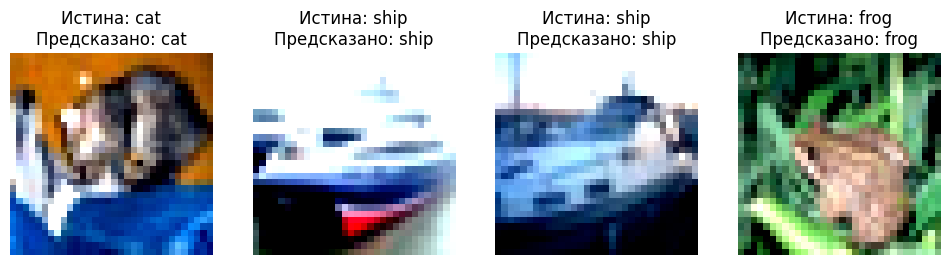

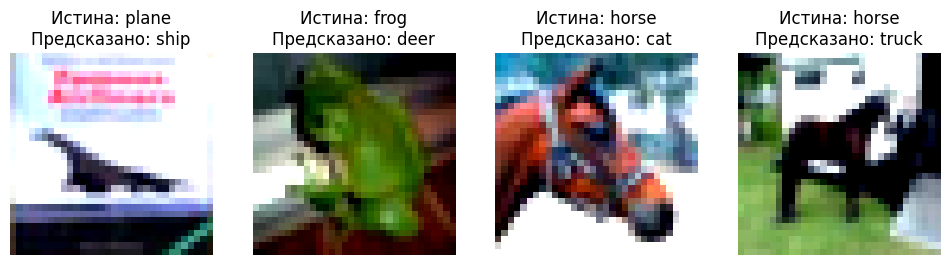

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# Переводим модель в режим оценки

model = best_by_acc[1]['model']

model.eval()

# Получаем один батч из тестового набора
dataiter = iter(test_loader)
images, labels = next(dataiter)

# Делаем предсказания
with torch.no_grad():
    outputs = model(images)
    _, predicted = torch.max(outputs, 1)

# Преобразуем тензоры в numpy для визуализации
images = images.numpy()
labels = labels.numpy()
predicted = predicted.numpy()

# Найдём индексы правильно и неправильно классифицированных
correct_indices = np.where(predicted == labels)[0]
incorrect_indices = np.where(predicted != labels)[0]

# Выберем по 4 примера (если есть)
num_to_show = 4
correct_to_show = correct_indices[:num_to_show] if len(correct_indices) >= num_to_show else correct_indices
incorrect_to_show = incorrect_indices[:num_to_show] if len(incorrect_indices) >= num_to_show else incorrect_indices

# Функция отображения
def show_examples(indices, title):
    plt.figure(figsize=(12, 3))
    for i, idx in enumerate(indices):
        plt.subplot(1, len(indices), i+1)
        # Восстанавливаем изображение из нормализации
        img = images[idx].transpose(1, 2, 0)
        img = img * 0.5 + 0.5  # обратная нормализация
        plt.imshow(np.clip(img, 0, 1))
        plt.title(f'Истина: {classes[labels[idx]]}\nПредсказано: {classes[predicted[idx]]}')
        plt.axis('off')
    plt.suptitle(title)
    plt.show()

# Показываем правильно классифицированные
if len(correct_to_show) > 0:
    show_examples(correct_to_show, '')
else:
    print("Нет правильно классифицированных примеров в этом батче.")

# Показываем неправильно классифицированные
if len(incorrect_to_show) > 0:
    show_examples(incorrect_to_show, '')
else:
    print("Нет неправильно классифицированных примеров в этом батче.")

## 6. Выводы

В этой ячейке напишите краткие выводы по работе:
- Почему CNN работает лучше MLP на CIFAR-10?
- Какие модификации архитектуры дали наибольший прирост качества и почему?
- Как изменилось количество параметров при различных изменениях?
- Что показала визуализация карт активации?

Используйте термины: рецептивное поле, локальность, разделение весов, регуляризация (dropout, batch norm), ёмкость модели, переобучение.

Новые навыки/умения/знания.
Пожелания по содержимому лекции ипрактики.

Ответ:

1) CNN работает лучше MLP на CIFAR-10, т.к. работает с локальными частями изображения, и рецептивное поле постепенно расширяется от простых контуров к более сложным частям объектов. Полносвязный персептрон работает с отдельными пикселями, не учитывая расположение объекта и его частей на картинке. Также CNN обладает лучшей обобщающей способностью, чем MLP.

2) Наибольший прирост качества дала модификация с увеличением числа каналов (Wider CNN). Скорее всего увеличение числа каналов позволило выявить больше локальных паттернов для каждого класса.

3) Depthwise CNN сильно уменьшает число параметров за счет небольшого уменьшения точности.

4) Карты активации показали контуры, цветовые переходы и локальные паттерны. На CIFAR-10 можно наблююдать разделение объекта от фона. Регуляризация в виде dropout и batch norm уменьшают риск переобучения.